# Implementation of the basic AR model

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [4]:
import bidict

In [5]:
import pymc as pm

In [6]:
import arviz as az

In [7]:
import pytensor as pt

In [8]:
from scipy import io

In [9]:
import os

## Data etc

In [10]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

In [11]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [12]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [13]:
user_id = 1610

In [14]:
features = pd.read_parquet('data/features.parquet')

In [15]:
features

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,ZMFCC10,ZMFCC11,ZMFCC12,XYCOS,XZCOS,YZCOS,XYCOR,XZCOR,YZCOR,RESULTANT
Eat_avg,0.000000,0.000000,0.000000,0.000000,0.201292,0.798652,0.000056,0.0,0.000000,0.0,...,0.238594,0.235816,0.232786,0.598902,0.996744,0.594817,-0.191686,-0.471820,-0.125553,9.347897
Eat_peak,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,0.297810,0.294343,0.290561,0.999991,NaN,0.999956,0.081228,-0.256704,0.189525,9.449970
Act_avg,0.043771,0.281425,0.164777,0.017486,0.200838,0.291648,0.000028,0.0,0.000028,0.0,...,0.274692,0.271494,0.268005,0.347796,0.524546,-0.031230,-0.226586,0.062980,-0.048911,9.721402
Act_peak,0.219091,0.668214,0.451855,0.138750,0.922439,1.000000,NaN,NaN,NaN,NaN,...,0.419315,0.414434,0.415597,-0.049084,0.574894,-0.251105,-0.015669,0.275879,0.186798,10.159496


### The target

In [16]:
df_eat = pd.read_parquet("data/df_eat.parquet")

In [17]:
df_act = pd.read_parquet("data/df_act.parquet")

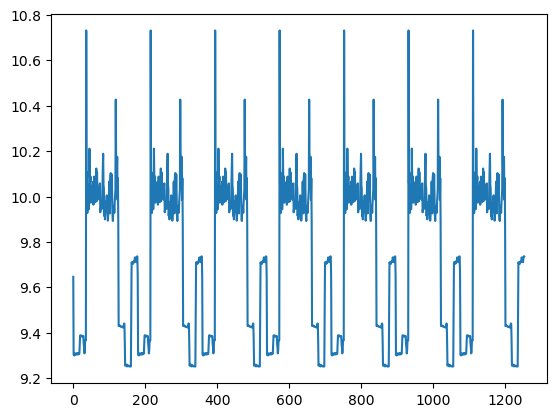

In [18]:
df_act.reset_index()['RESULTANT'].plot();

In [70]:
df_eat.columns

Index(['ACTIVITY', 'X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9',
       'Y0', 'Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Z0', 'Z1',
       'Z2', 'Z3', 'Z4', 'Z5', 'Z6', 'Z7', 'Z8', 'Z9', 'XAVG', 'YAVG', 'ZAVG',
       'XPEAK', 'YPEAK', 'ZPEAK', 'XABSOLDEV', 'YABSOLDEV', 'ZABSOLDEV',
       'XSTANDDEV', 'YSTANDDEV', 'ZSTANDDEV', 'XVAR', 'YVAR', 'ZVAR', 'XMFCC0',
       'XMFCC1', 'XMFCC2', 'XMFCC3', 'XMFCC4', 'XMFCC5', 'XMFCC6', 'XMFCC7',
       'XMFCC8', 'XMFCC9', 'XMFCC10', 'XMFCC11', 'XMFCC12', 'YMFCC0', 'YMFCC1',
       'YMFCC2', 'YMFCC3', 'YMFCC4', 'YMFCC5', 'YMFCC6', 'YMFCC7', 'YMFCC8',
       'YMFCC9', 'YMFCC10', 'YMFCC11', 'YMFCC12', 'ZMFCC0', 'ZMFCC1', 'ZMFCC2',
       'ZMFCC3', 'ZMFCC4', 'ZMFCC5', 'ZMFCC6', 'ZMFCC7', 'ZMFCC8', 'ZMFCC9',
       'ZMFCC10', 'ZMFCC11', 'ZMFCC12', 'XYCOS', 'XZCOS', 'YZCOS', 'XYCOR',
       'XZCOR', 'YZCOR', 'RESULTANT'],
      dtype='object')

In [62]:
df_eat["ACTIVITY"].unique()

array(['H', 'I', 'J', 'K', 'L'], dtype=object)

## Multivariate A-R Model

We can treat the learned characteristics of all the timeseries data observed to-date, as well as the other covariates observed at the same time step, as informative about the structure of the unrealised current state of the predictor. 


In [104]:
test_df = df_eat[["ACTIVITY", "ZSTANDDEV", "ZPEAK", "RESULTANT"]]
test_df["ZSTANDDEV_lag1"] = test_df.groupby(["ACTIVITY"])["ZSTANDDEV"].shift(1)
test_df["ZPEAK_lag1"] = test_df.groupby(["ACTIVITY"])["ZPEAK"].shift(1)
test_df["RESULTANT_lag1"] = test_df.groupby(["ACTIVITY"])["RESULTANT"].shift(1)
test_df = test_df.dropna()

id_indx, unique_ids = pd.factorize(test_df["ACTIVITY"])
coords = {"ids": unique_ids, "obs": range(len(test_df["RESULTANT"]))}
with pm.Model(coords=coords) as model:
    res_lag1_data = pm.MutableData("res_lag1_data", test_df["RESULTANT_lag1"].values)
    zpeak_data = pm.MutableData("zpeak_data", test_df["ZPEAK"].values)
    zpeak_lag1_data = pm.MutableData("zpeak_lag1_data", test_df["ZPEAK_lag1"].values)
    zstanddev_data = pm.MutableData("zstanddev_data", test_df["ZSTANDDEV"].values)
    zstanddev_lag1_data = pm.MutableData("zstanddev_lag1_data", test_df["ZSTANDDEV_lag1"].values)

    ## Level 1
    global_intercept = pm.Normal("global_intercept", 10, 2)
    global_sigma = pm.HalfStudentT("global_sigma", 1, 3)
    global_res_lag1_beta = pm.Normal("global_res_lag1_beta", 0, 1)
    global_zpeak_beta = pm.Normal("global_zpeak_beta", 0, 1)
    global_zpeak_lag1_beta = pm.Normal("global_zpeak_lag1_beta", 0, 1)
    global_zstanddev_beta = pm.Normal("global_zstanddev_beta", 0, 1)
    global_zstanddev_lag1_beta = pm.Normal("global_zstanddev_lag1_beta", 0, 1)

    subject_intercept_sigma = pm.HalfNormal("subject_intercept_sigma", 2)

    ## Level 2
    subject_intercept = pm.Normal("subject_intercept", 0, subject_intercept_sigma, dims="ids")

    growth_model = pm.Deterministic(
        "growth_model",
        (global_intercept + subject_intercept[id_indx])
        + global_res_lag1_beta * res_lag1_data
        + global_zpeak_beta * zpeak_data
        + global_zpeak_lag1_beta * zpeak_lag1_data
        + global_zstanddev_beta * zstanddev_data
        + global_zstanddev_lag1_beta * zstanddev_lag1_data,
    )
    
    outcome = pm.Normal(
        "outcome", growth_model, global_sigma, observed=test_df["RESULTANT"].values, dims="obs"
    )
    
    idata_m2 = pm.sample_prior_predictive()
    idata_m2.extend(
        pm.sample(random_seed=100, target_accept=0.95, idata_kwargs={"log_likelihood": True})
    )
    idata_m2.extend(pm.sample_posterior_predictive(idata_m2))

/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_21281/3956237474.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df["ZSTANDDEV_lag1"] = test_df.groupby(["ACTIVITY"])["ZSTANDDEV"].shift(1)
/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_21281/3956237474.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df["ZPEAK_lag1"] = test_df.groupby(["ACTIVITY"])["ZPEAK"].shift(1)
/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_21281/3956237474.py:4: SettingWithCopyWarning

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 639 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Sampling: [outcome]


ImportError: This function requires the python library graphviz, along with binaries. The easiest way to install all of this is by running

	conda install -c conda-forge python-graphviz

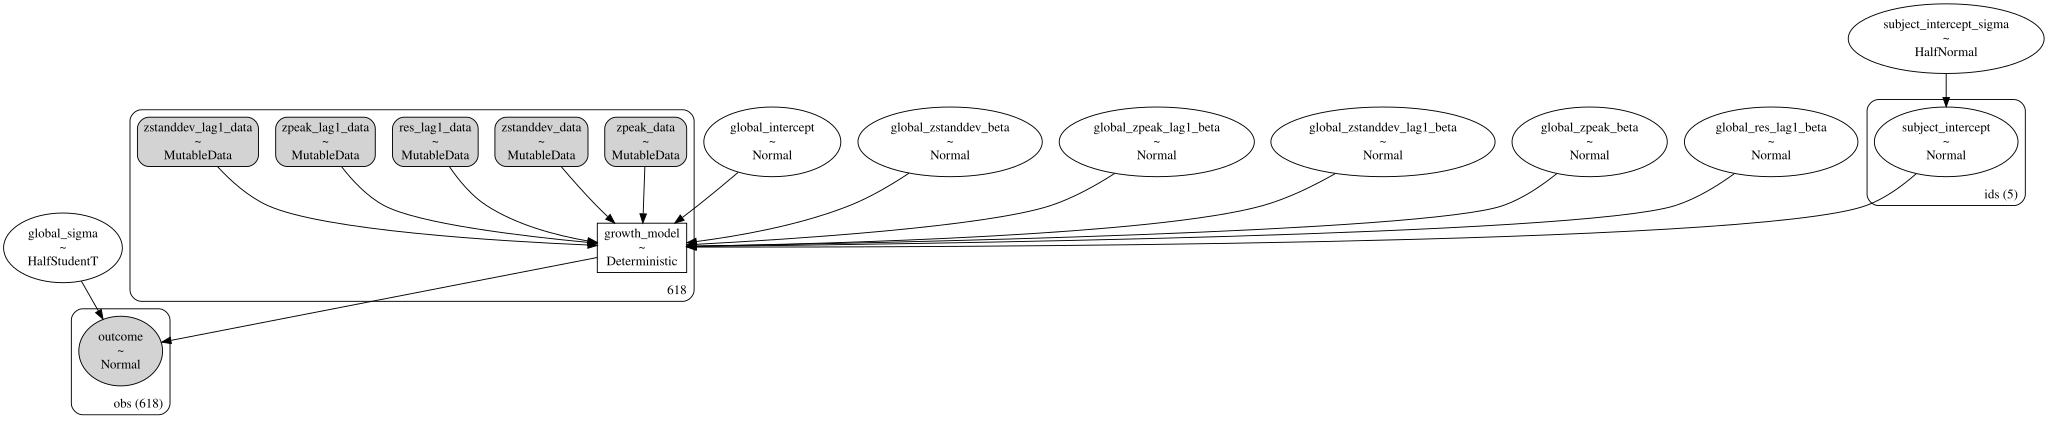

In [109]:
pm.model_to_graphviz(model)

In [106]:
idata_m2

Inference data with groups:
	> posterior
	> posterior_predictive
	> log_likelihood
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

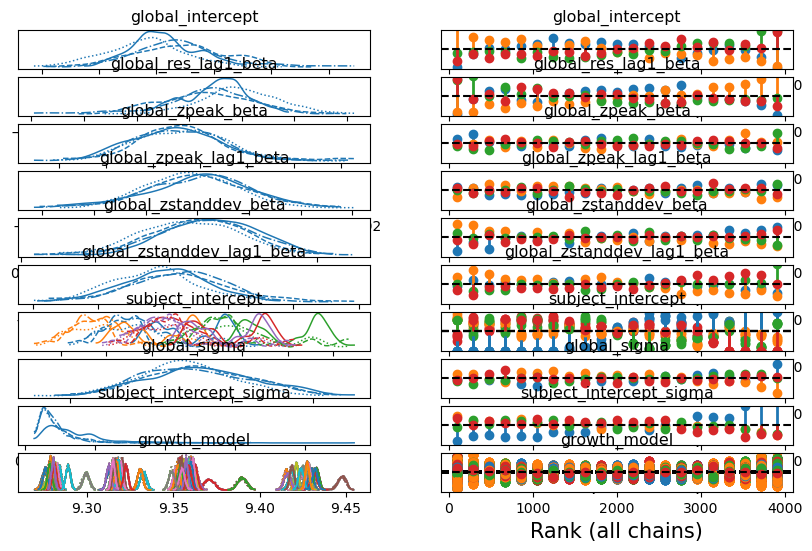

In [107]:
az.plot_trace(idata_m2, figsize=(10, 6), kind="rank_vlines");

In [114]:
az.summary(idata_m2)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
global_intercept,9.092,0.385,8.372,9.845,0.044,0.031,77.0,173.0,1.07
global_res_lag1_beta,0.027,0.041,-0.046,0.110,0.005,0.003,78.0,174.0,1.07
global_zpeak_beta,-0.000,0.000,-0.000,0.000,0.000,0.000,165.0,242.0,1.03
global_zpeak_lag1_beta,-0.001,0.000,-0.001,-0.000,0.000,0.000,172.0,275.0,1.02
global_zstanddev_beta,0.744,0.064,0.629,0.865,0.005,0.004,160.0,427.0,1.02
...,...,...,...,...,...,...,...,...,...
growth_model[613],9.359,0.001,9.357,9.362,0.000,0.000,371.0,1102.0,1.02
growth_model[614],9.358,0.001,9.356,9.359,0.000,0.000,3084.0,2670.0,1.00
growth_model[615],9.355,0.001,9.353,9.357,0.000,0.000,3167.0,2892.0,1.00
growth_model[616],9.355,0.002,9.352,9.358,0.000,0.000,246.0,355.0,1.02


ValueError: Dataset.plot cannot be called directly. Use an explicit plot method, e.g. ds.plot.scatter(...)

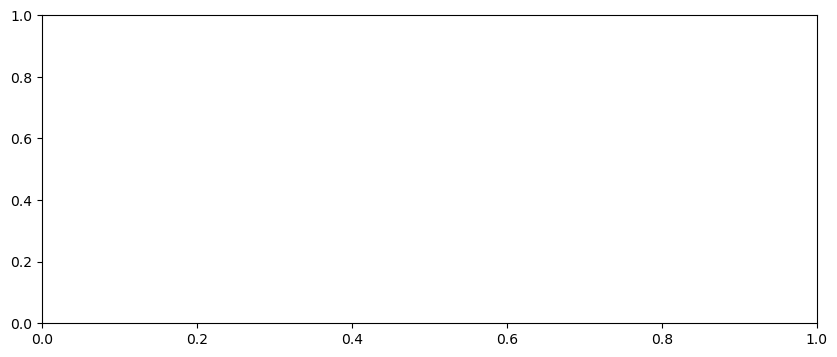

In [111]:
fig, ax = plt.subplots(figsize=(10, 4))
idata_m2.posterior.mean(["chain", "draw"]).plot(ax=ax, label="Posterior Mean AR level")
ax.plot(df_eat.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
ax.legend()
ax.set_title("Fitted AR process\nand observed data");

### Predictions

 - Forecast from the  posterior given the observations so far

In [61]:
prediction_length = 50
n = prediction_length - df_act.shape[0]
obs = list(range(prediction_length))

with AR:
    ## We need to have coords for the observations minus the lagged term to correctly centre the prediction step
    AR.add_coords({"obs_id_fut_1": range(df_act.RESULTANT.values.shape[0] - 1, 50, 1)})
    AR.add_coords({"obs_id_fut": range(df_act.RESULTANT.values.shape[0], 50, 1)})
    # condition on the learned values of the AR process
    # initialise the future AR process precisely at the last observed value in the AR process
    # using the special feature of the dirac delta distribution to be 0 everywhere else.
    ar1_fut = pm.AR(
        "ar1_fut",
        init_dist=pm.DiracDelta.dist(ar1[..., -1]),
        rho=coefs,
        sigma=sigma,
        constant=True,
        dims="obs_id_fut_1",
    )
    yhat_fut = pm.Normal("yhat_fut", mu=ar1_fut[1:], sigma=sigma, dims="obs_id_fut")
    # use the updated values and predict outcomes and probabilities:
    idata_preds = pm.sample_posterior_predictive(
        idata_ar, var_names=["likelihood", "yhat_fut"], predictions=True, random_seed=100
    )

Sampling: [ar1_fut, likelihood, yhat_fut]


OverflowError: can't convert negative value to unsigned int
Apply node that caused the error: Scan{scan_fn, while_loop=False, inplace=all}(-1, SetSubtensor{:stop}.0, RandomGeneratorSharedVariable(<Generator(PCG64) at 0x306EB1B60>), sigma, SpecifyShape.0, Subtensor{i}.0)
Toposort index: 9
Inputs types: [TensorType(int32, shape=()), TensorType(float64, shape=(None,)), RandomGeneratorType, TensorType(float64, shape=()), TensorType(float64, shape=(1,)), TensorType(float64, shape=())]
Inputs shapes: [(), (0,), 'No shapes', (), (1,), ()]
Inputs strides: [(), (0,), 'No strides', (), (-8,), ()]
Inputs values: [array(-1, dtype=int32), array([], dtype=float64), Generator(PCG64) at 0x306EB1B60, array(0.03688665), array([-0.04475368]), array(9.76799348)]
Outputs clients: [[Subtensor{start:}(Scan{scan_fn, while_loop=False, inplace=all}.0, 1)], ['output']]

HINT: Re-running with most PyTensor optimizations disabled could provide a back-trace showing when this node was created. This can be done by se

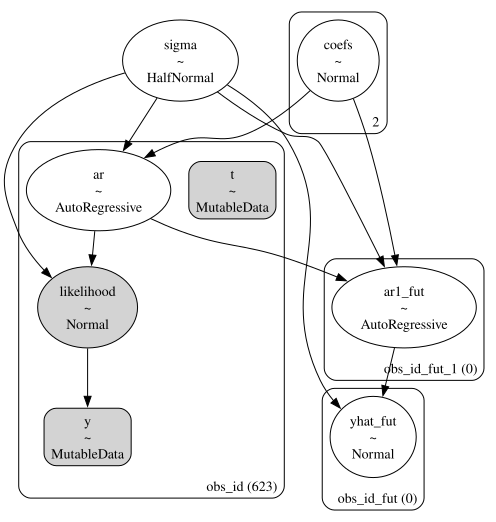

In [52]:
pm.model_to_graphviz(AR)